In [2]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.io.fits as fits
import fitsio
from scipy.stats import gaussian_kde
import somoclu
import matplotlib.cm
import pickle
import pandas as pd
import healpy as hp
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import treecorr
import gc
import matplotlib.colors
import matplotlib.patches as mpatches
import seaborn
from time import time
import scipy
import matplotlib as mpl
from operator import attrgetter
from scipy.sparse import csr_matrix
def one_dim_index(coord, grid_size):
    if (coord[0]>=grid_size).any() or (coord[1]>=grid_size).any():
        raise Exception('Index larger than grid size!')
    return(coord.T[0] + grid_size * coord.T[1])
def two_dim_index(one_dim_index, grid_size):
    if one_dim_index>=grid_size**2:
        raise Exception('Index larger than grid size squared!')
    return(one_dim_index%grid_size, int(one_dim_index/grid_size))
class MidpointNormalize(mpl.colors.Normalize):
    def __init__(self, vmin, vmax, midpoint=0, clip=False):
        self.midpoint = midpoint
        mpl.colors.Normalize.__init__(self, vmin, vmax, clip)

    def __call__(self, value, clip=None):
        normalized_min = max(0, 1 / 2 * (1 - abs((self.midpoint - self.vmin) / (self.midpoint - self.vmax))))
        normalized_max = min(1, 1 / 2 * (1 + abs((self.vmax - self.midpoint) / (self.midpoint - self.vmin))))
        normalized_mid = 0.5
        x, y = [self.vmin, self.midpoint, self.vmax], [normalized_min, normalized_mid, normalized_max]
        return np.ma.masked_array(np.interp(value, x, y))
def plot_som(nodes_means, file = None):
    fig = plt.figure(figsize=(10,8))
    c_2d = np.array([two_dim_index(i, 200) for i in range(200**2)])
    c = np.where(c_2d.T[0]<150)
    d = np.where(c_2d.T[0]>=150)
    c_2d.T[0][c] += 50
    c_2d.T[0][d] -= 150
    plt.scatter(c_2d.T[0], c_2d.T[1], s = 5, c=nodes_means, cmap='jet', vmin=0, vmax=3)
    cb = plt.colorbar()
    cb.set_label('redshift', size=16)
    cb.ax.tick_params(labelsize=16)
    plt.xlim((0,200))
    plt.ylim((0,200))
    if file:
        plt.savefig(file)
    plt.show()
def plot_som2_2(clusters, nodes_means, file=None, dpi = 300, title = None):
    fig, ax = plt.subplots(1,1,figsize=(10,8))
    cmap = plt.get_cmap('jet', np.max(nodes_means)-np.min(nodes_means)+1)
    for i in range(len(set(clusters))):
        p = plot_cluster_c(clusters,i, ax, nodes_means)
    c_2d = np.array([two_dim_index(i, 200) for i in range(200**2)])
    a = np.where(c_2d.T[0]<150)
    b = np.where(c_2d.T[0]>=150)
    c_2d.T[0][a] += 50
    c_2d.T[0][b] -= 150
    mat = ax.scatter(c_2d.T[0], c_2d.T[1], s = 5, marker = 's', c=nodes_means, cmap=cmap, vmin = np.min(nodes_means)-.5, vmax = np.max(nodes_means)+.5)
    cb = plt.colorbar(mat, ax=ax)
    ticks = np.arange(np.min(nodes_means),np.max(nodes_means)+1)
    labels = np.copy(ticks)
    if ticks[0] == 0:
        labels[0] = -1
    cb.set_ticks(ticks, labels = labels)
    cb.set_label('redshift bin', size=20)
    cb.ax.tick_params(labelsize=20)
    ax.set_xlim((0,200))
    ax.set_ylim((0,200))
    ax.tick_params(axis='x', labelsize= 16)
    ax.tick_params(axis='y', labelsize= 16)
    ax.set_xlabel('SOM dimension 1', size = 18)
    ax.set_ylabel('SOM dimension 2', size = 18)
#     plt.xlabel(fontsize=18)
#     plt.ylabel(fontsize=18)
    if title:
        ax.set_title(title, size = 22)
    plt.tight_layout()
    if file:
        fig.savefig(file, dpi = dpi)
def compute_M(data):
    cols = np.arange(data.size)
    return csr_matrix((cols, (data.ravel(), cols)),
                      shape=(data.max() + 1, data.size))
def get_indices_sparse(data):
    M = compute_M(data)
    return [np.unravel_index(row.data, data.shape)[0] for row in M]

def plot_cluster_c(clusters, i, ax, nodes_means):
    c = np.where(clusters == i)[0]
    c_2d = np.array([two_dim_index(c[j], 200) for j in range(len(c))])
    a = np.where(c_2d.T[0]<150)
    b = np.where(c_2d.T[0]>=150)
    c_2d.T[0][a] += 50
    c_2d.T[0][b] -= 150
    colour = np.full(len(c),np.mean(nodes_means[c][np.isfinite(nodes_means[c])]))
    ax.scatter(c_2d.T[0], c_2d.T[1], s = 5, c=colour, cmap='jet', vmin=0, vmax=3)

In [3]:
%%time
with open('data/correlations_dl/dd.pkl', 'rb') as f:
    dd = pickle.load(f)
with open('data/correlations_dl/dr.pkl', 'rb') as f:
    dr = pickle.load(f)
with open('data/correlations_dl/rd.pkl', 'rb') as f:
    rd = pickle.load(f)
with open('data/correlations_dl/rr.pkl', 'rb') as f:
    rr = pickle.load(f)

CPU times: user 34.5 s, sys: 13.4 s, total: 47.9 s
Wall time: 53.9 s


In [5]:
accept = np.load('data/accept_fc.npy')
photometric_sample = np.load('data/photometric_sample_fc.npy')
reference_sample = np.load('data/reference_sample_fc.npy')
reference_labels = np.load('data/reference_labels_fc_fc.npy')

true_redshift = pd.read_parquet('data/full_catalogue.parquet', columns= ['redshift'])
true_redshift.drop(index=true_redshift.index[-1],axis=0,inplace=True)
true_redshift.drop(index=np.arange(len(accept))[accept==False],axis=0,inplace=True)
true_redshift.reset_index(inplace = True, drop = True)

true_redshift_photometric = true_redshift.drop(index = reference_sample, inplace = False)
true_redshift_photometric = true_redshift_photometric['redshift'].to_numpy()

# photometric_redshift = pd.read_parquet('data/full_catalogue.parquet', columns= ['photoz_mode'])
# photometric_redshift.drop(index=photometric_redshift.index[-1],axis=0,inplace=True)
# photometric_redshift.drop(index=np.arange(len(accept))[accept==False],axis=0,inplace=True)
# photometric_redshift.reset_index(inplace = True, drop = True)
# photometric_redshift.drop(index = reference_sample, inplace = True)
# photometric_redshift.reset_index(inplace = True, drop = True)
# photometric_redshift = photometric_redshift['photoz_mode'].to_numpy()
# photometric_labels = (photometric_redshift/0.2).astype(int)
# photometric_labels[photometric_labels>10] = 10

# photometric_labels_initial = np.zeros(photometric_labels.shape[0])
# for i in range(200**2):
#     idx = node_indices_gal2[i]
#     if len(idx) > 0:
#         z, c = np.unique(photometric_labels[idx], return_counts=True)
#         idx_max = np.argmax(c)
#         photometric_labels_initial[idx] = z[idx_max]

# Load precalculated arrays
photometric_labels_initial = np.load('data/photometric_labels_initial_fc_200_ext.npy')
node_indices = np.load('data/node_indices_fc.npy')
weighted_clusters = np.load('data/weighted_clusters_5c_1t200.npy')

In [6]:
%%time
# nodes_labels_initial = np.zeros(200**2)
# for i in range(200**2):
#     if i%5000 == 0:
#         print(i)
#     idx = np.where(node_indices == i)[0]
#     values, counts = np.unique(photometric_labels_initial[idx], return_counts=True)
#     z_bin = values[np.argmax(counts)]
#     nodes_labels_initial[i] = z_bin
# np.save('data/nodes_labels_initial_fc_200_ext.npy', nodes_labels_initial)

# Load precalculated array
nodes_labels_initial = np.load('data/nodes_labels_initial_fc_200_ext.npy').astype(int)

CPU times: user 638 µs, sys: 1.25 ms, total: 1.89 ms
Wall time: 1.26 ms


In [7]:
%%time
min_sep = 0.01              # minimum separation (treecorr)
max_sep = 0.1                # maximum separation (treecorr)
sep_units = 'degrees'        # separation unit (treecorr)
nbins = 1
bins = np.array([photometric_labels_initial == i for i in range(11)])
bins_nodes = np.array([np.unique(node_indices[bins[i]]) for i in range(11)])
xi_bins = np.zeros((11,11))
xi_bins_manual = np.zeros((11,11))
for j in range(11):
    for i in range(11):
        # treecorr calculation
        dd_tot = treecorr.NNCorrelation(min_sep=min_sep,max_sep=max_sep,nbins=nbins,sep_units=sep_units)
        dr_tot = treecorr.NNCorrelation(min_sep=min_sep,max_sep=max_sep,nbins=nbins,sep_units=sep_units)
        rd_tot = treecorr.NNCorrelation(min_sep=min_sep,max_sep=max_sep,nbins=nbins,sep_units=sep_units)
        rr_tot = treecorr.NNCorrelation(min_sep=min_sep,max_sep=max_sep,nbins=nbins,sep_units=sep_units)
        bins_nodes_ = bins_nodes[i]
        DD = 0
        DR = 0
        RD = 0
        RR = 0
        for k in bins_nodes_:
            dd_tot.__iadd__(dd[j,k])
            dr_tot.__iadd__(dr[j,k])
            rd_tot.__iadd__(rd[j,k])
            rr_tot.__iadd__(rr[j,k])
            
            DD += dd[j,k].npairs
            DR += dr[j,k].npairs
            RD += rd[j,k].npairs
            RR += rr[j,k].npairs
        dd_tot.finalize()
        dr_tot.finalize()
        rd_tot.finalize()
        rr_tot.finalize()
        xi_bins[i,j] = dd_tot.calculateXi(rr=rr_tot,dr=dr_tot,rd=rd_tot)[0][0]
    
        # manual calculation
        n_phot = len(np.where(photometric_labels_initial==i)[0])
        n_ref = len(np.where(reference_labels==j)[0])
        DD /= (n_phot * n_ref)
        DR /= (n_phot * 10*n_ref)
        RD /= (10*n_phot * n_ref)
        RR /= (10*n_phot * 10*n_ref)
        xi_bins_manual[i,j] = (DD - DR - RD + RR) / RR
        
        # treecorr calculation and manual calculation should give the same result

<timed exec>:6: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


CPU times: user 25.7 s, sys: 7.06 s, total: 32.7 s
Wall time: 49.3 s


In [8]:
np.diag(xi_bins)

array([0.01092194, 0.02154098, 0.02564155, 0.02869826, 0.02947713,
       0.03440071, 0.02712075, 0.03436128, 0.01519845, 0.04005178,
       0.01110604])

In [9]:
np.diag(xi_bins_manual)

array([0.01092194, 0.02154098, 0.02564155, 0.02869826, 0.02947713,
       0.03440071, 0.02712075, 0.03436128, 0.01519845, 0.04005178,
       0.01110604])

In [10]:
xi_ref_auto = np.load('data/xi_ref_auto.npy')

/var/folders/ms/ww9f47ts7x9gb6zr4x2j3xhh0000gn/T/ipykernel_39926/3663336701.py:26: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels((ax.get_xticks()+1).astype(int))
/var/folders/ms/ww9f47ts7x9gb6zr4x2j3xhh0000gn/T/ipykernel_39926/3663336701.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels((ax.get_yticks()+1).astype(int))


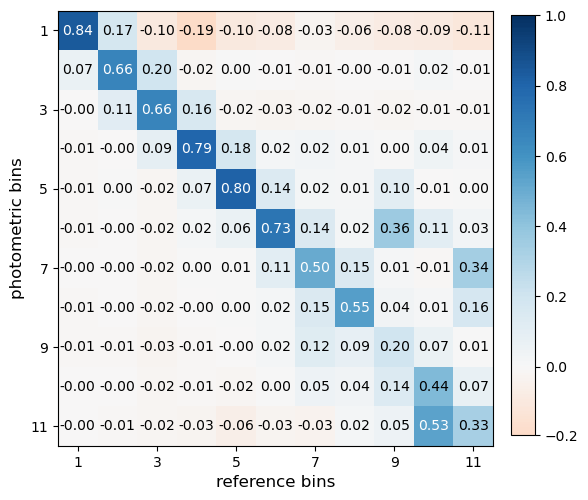

In [11]:
n_bins = 10
cmap = 'RdBu'

fig, ax = plt.subplots(1,1,figsize = (6,6))
xi_plot = np.copy(xi_bins)
for i in range(n_bins+1):
    xi_plot[i] /= xi_ref_auto

vmin = xi_plot.min()
vmax = xi_plot.max()

vmax = 1
norm = MidpointNormalize(vmin=vmin, vmax=vmax, midpoint=0)
xi_plot = xi_plot.T
m1 = ax.imshow(xi_plot, cmap = cmap, norm=norm)
for (i, j), z in np.ndenumerate(xi_plot):
    if z < 0.5:
        ax.text(j, i, '{:0.2f}'.format(z), ha='center', va='center', fontsize = 10, color = 'black')
    else:
        ax.text(j, i, '{:0.2f}'.format(z), ha='center', va='center', fontsize = 10, color = 'white')
    ax.set_xlabel('reference bins', fontsize = 12)
    ax.set_ylabel('photometric bins', fontsize = 12)
ax.tick_params(axis='x', labelsize= 10)
ax.tick_params(axis='y', labelsize= 10)
ax.xaxis.set_ticks_position('bottom')
ax.set_xticklabels((ax.get_xticks()+1).astype(int))
ax.set_yticklabels((ax.get_yticks()+1).astype(int))
fig.subplots_adjust(right=0.85)
cbar_ax = fig.add_axes([0.88, 0.15, 0.04, 0.7])
fig.colorbar(m1, cax=cbar_ax)
plt.show()

In [12]:
%%time
nodes_mean_true = np.zeros(200**2)
nodes_size = np.zeros(200**2)
for i in range(len(node_indices)):
    idx = node_indices[i]
    nodes_mean_true[idx] += true_redshift_photometric[i]
    nodes_size[idx] += 1
nodes_mean_true /= nodes_size

CPU times: user 36.3 s, sys: 607 ms, total: 36.9 s
Wall time: 38.6 s


In [13]:
%%time
nodes_mean_phot = np.zeros(200**2)
nodes_size = np.zeros(200**2)
for i in range(len(node_indices)):
    idx = node_indices[i]
    nodes_mean_phot[idx] += photometric_redshift[i]
    nodes_size[idx] += 1
nodes_mean_phot /= nodes_size

NameError: name 'photometric_redshift' is not defined

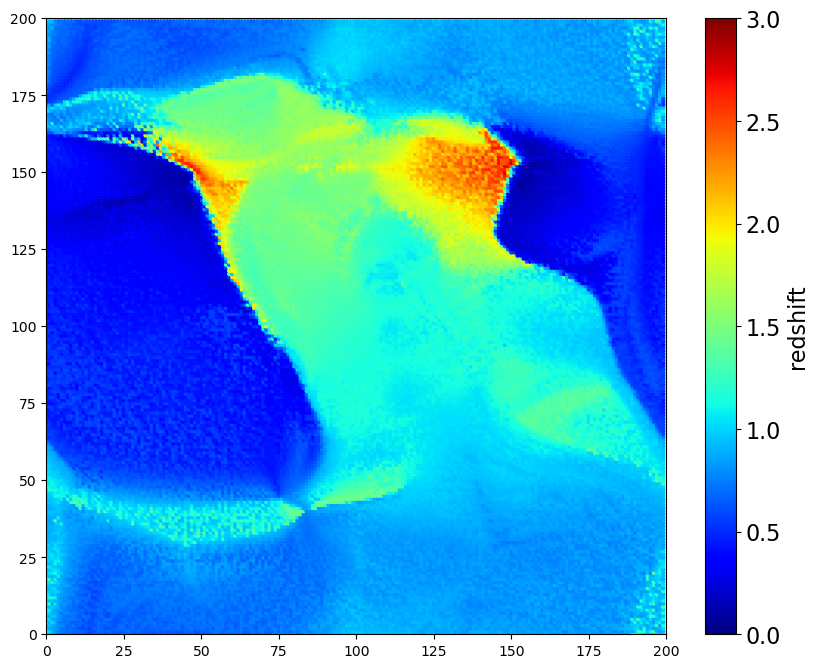

In [14]:
plot_som(nodes_mean_true)

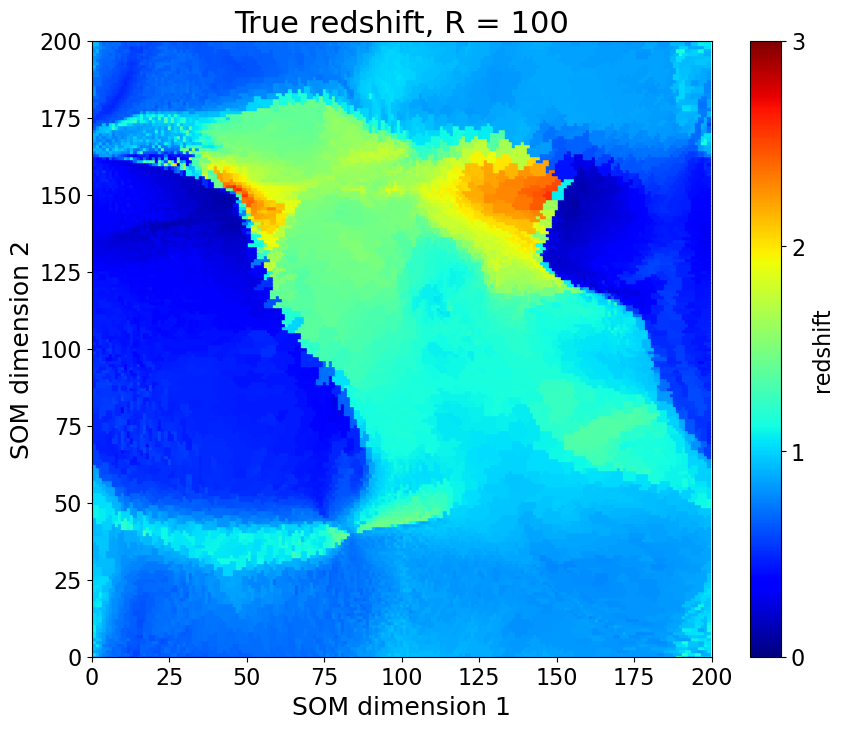

In [15]:
R=100

c_2d = np.array([two_dim_index(i, 200) for i in range(200**2)])
colours = np.zeros(200**2)
l = len(set(weighted_clusters[R,:]))
for i in range(l):
    c = np.where(weighted_clusters[R,:] == i)[0]
    colours[c] = np.mean(nodes_mean_true[c][np.isfinite(nodes_mean_true[c])])
    
fig, ax = plt.subplots(1,1,figsize=(10,8))
a = np.where(c_2d.T[0]<150)
b = np.where(c_2d.T[0]>=150)
c_2d.T[0][a] += 50
c_2d.T[0][b] -= 150
p = ax.scatter(c_2d.T[0], c_2d.T[1], s = 5, marker = 's', c=colours, cmap='jet', vmin=0, vmax=3)
ax.set_xlim((0,200))
ax.set_ylim((0,200))
cb = plt.colorbar(p, ticks=np.arange(0,3.1))
cb.set_label('redshift', size=16)
cb.ax.tick_params(labelsize=16)
ax.tick_params(axis='x', labelsize= 16)
ax.tick_params(axis='y', labelsize= 16)
ax.set_xlabel('SOM dimension 1', size = 18)
ax.set_ylabel('SOM dimension 2', size = 18)
ax.set_title('True redshift, R = %d'%R, size = 22)
plt.show()

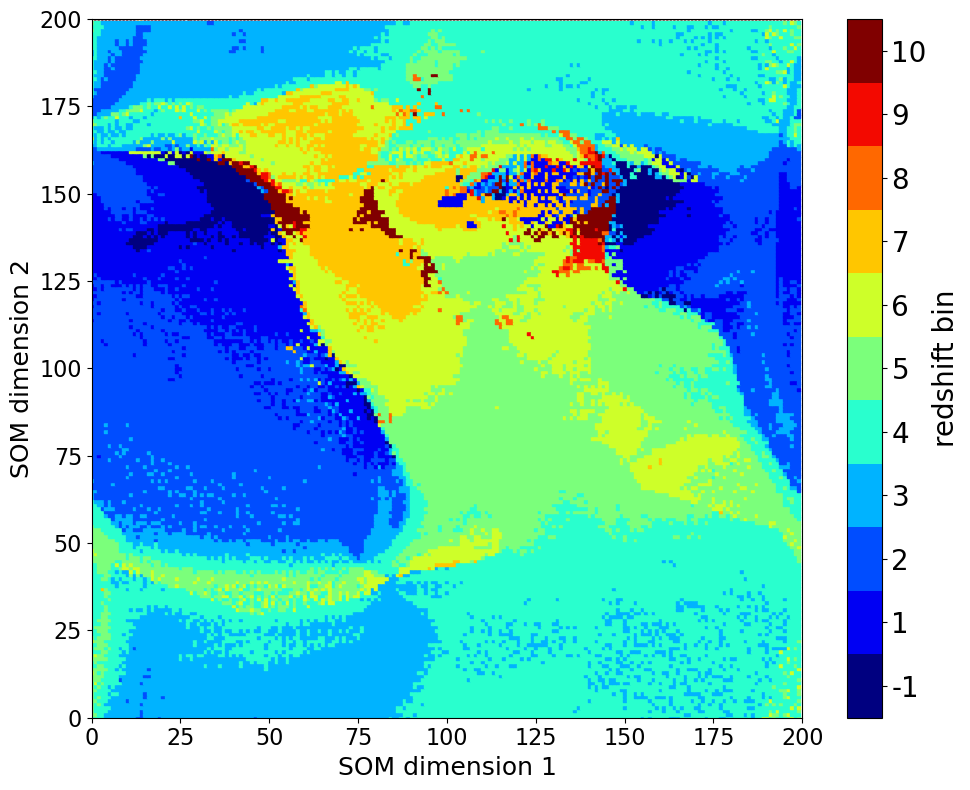

In [16]:
plot_som2_2(weighted_clusters[50], nodes_labels_initial)

In [17]:
z_grid = np.linspace(0,3,300)
kde_phot = []
for i in range(11):
    true_z = true_redshift_photometric[np.where(photometric_labels_initial == i)[0]]
    kde_phot.append(gaussian_kde(true_z))
nz_ini = []
for i in range(11):
    print(i)
    nz_ini.append(kde_phot[i].evaluate(z_grid))

0
1
2
3
4
5
6
7
8
9
10


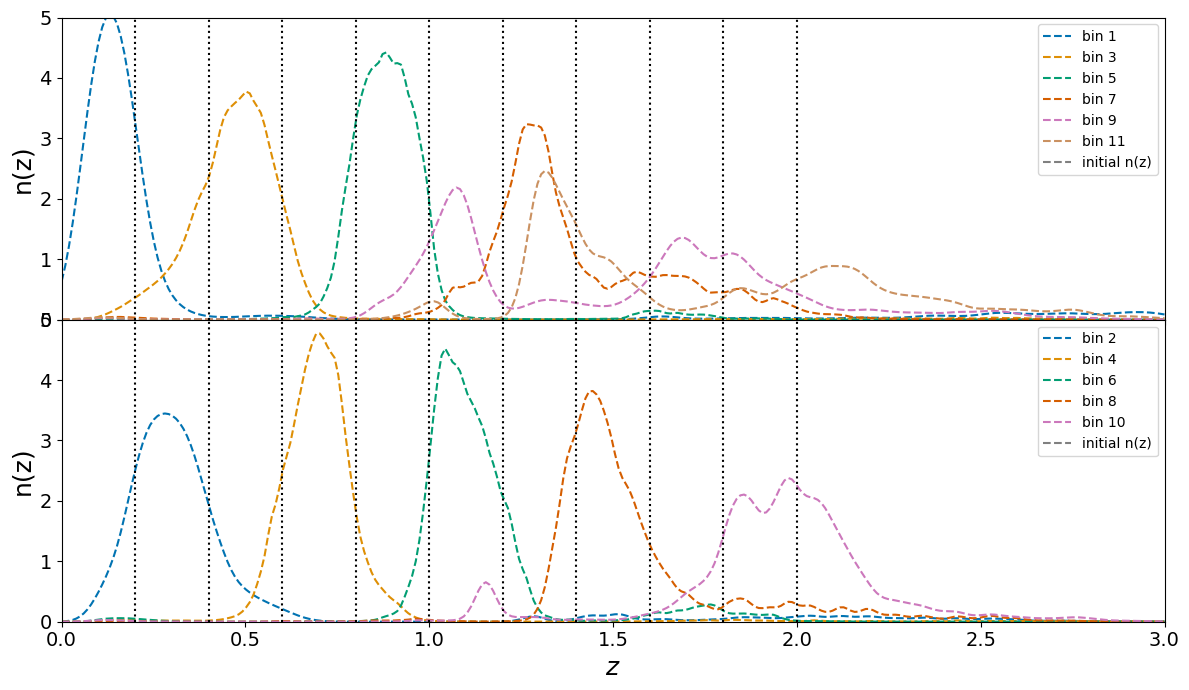

In [18]:
import seaborn as sns
colours = sns.color_palette('colorblind')
idx = [0,0,1,1,2,2,3,3,4,4,5,5]
z_grid = np.linspace(0,3,300)
fig, ax = plt.subplots(2,1,figsize=(12,7), sharex=True)
for i in range(11):
    if i%2 ==0:
        ax[0].plot(z_grid, nz_ini[i], label = 'bin %d'%(i+1),color=colours[idx[i]], linestyle='dashed')
    else:
        ax[1].plot(z_grid, nz_ini[i], label = 'bin %d'%(i+1),color=colours[idx[i]], linestyle='dashed')
xposition = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0]
for xc in xposition:
    ax[0].axvline(x=xc, color='black', linestyle='dotted')
    ax[1].axvline(x=xc, color='black', linestyle='dotted')
ax[0].plot([0], [0], label='initial n(z)', color='grey', linestyle = 'dashed')
ax[1].plot([0], [0], label='initial n(z)', color='grey', linestyle = 'dashed')
# ax[0].set_xlabel(r'$z$', fontsize = 18)
ax[0].set_ylabel(r'n(z)', fontsize = 18)
ax[0].tick_params(axis='x', labelsize= 14)
ax[0].tick_params(axis='y', labelsize= 14)
ax[0].set_xlim((0,3))
ax[0].set_ylim((0,5))
ax[1].set_xlabel(r'$z$', fontsize = 18)
ax[1].set_ylabel(r'n(z)', fontsize = 18)
ax[1].tick_params(axis='x', labelsize= 14)
ax[1].tick_params(axis='y', labelsize= 14)
ax[1].set_xlim((0,3))
ax[1].set_ylim((0,5))
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.subplots_adjust(wspace=0, hspace=0)
plt.show()